# Лабораторна 1. Основні бібліотеки. Лінійні моделі навчання.

В цій лабораторній роботі студенти:
- ознайомлюються з сервісом Colab;
- ознайомлюються з базовими бібліотеками для машинного навчання;
- тренують неглибокі лінійні моделі машинного навчання на базі простих регресій: лінійна, логістична, поліноміальна.

## 0. Налаштування середовища

### 0.0. Імпортуємо залежності

In [ ]:
import sys
import os
import random
import numpy as np
import torch
import pandas as pd
import matplotlib.pyplot as plt

### 0.1. Перевіряємо чи ми точно в Colab

In [ ]:
IN_COLAB = "google.colab" in sys.modules
print("Running in Colab:", IN_COLAB)

assert IN_COLAB, f"Ця лаба має вокинуватися в Google Colab (https://colab.research.google.com/)"

Running in Colab: True


### 0.2. Фіксуємо всі джерела випадковості.
На GPU повна детермінованість трохи сповільнює тренування
(`cudnn.deterministic = True` вимикає частину швидких алгоритмів) —
тут це не критично, адже дані й модель дрібні.

In [ ]:
SEED = 42

def set_seed(seed: int = SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

**Вправа 1.** Скористайся вбудованим модулем `random`. Спробуй `random.randint(1, 100)` і `random.shuffle()` на списку — випадковість буває не лише в числі, а й у перестановці. Згенеруй обома способами двічі ДО виклику `set_seed()` — переконайся, що результати різні. Потім ще двічі **ПІСЛЯ** з викликом set_seed() після кожної генерації і потім ще двічі **без проміжного виклику** `set_seed()`.

Після клітинки з кодом створи клітинку з маркдауном і поясни що відбувається після `set_seed()` і як це проявляється в результатах виконання коду.

In [ ]:
numbers = list(range(10))  # список для shuffle

random_number = random.randint(1, 100)
random.shuffle(numbers)

print("Перше випадкове число до виклику set_seed():", random_number)
print("Перша перестановка чисел до виклику set_seed():", numbers)

numbers = list(range(10))
random_number = random.randint(1, 100)
random.shuffle(numbers)

print("Друге випадкове число до виклику set_seed():", random_number)
print("Друга перестановка чисел до виклику set_seed():", numbers)

numbers = list(range(10))
set_seed()
print("\nSeed зафіксовано:", SEED)

random_number = random.randint(1, 100)
set_seed()
random.shuffle(numbers)

print("Перше випадкове число після виклику set_seed() після кожної генерації:", random_number)
print("Перша перестановка чисел після виклику set_seed() після кожної генерації:", numbers)

numbers = list(range(10))
set_seed()
random_number = random.randint(1, 100)
set_seed()
random.shuffle(numbers)

print("Друге випадкове число після виклику set_seed() після кожної генерації:", random_number)
print("Друга перестановка чисел після виклику set_seed() після кожної генерації:", numbers)

numbers = list(range(10))
set_seed()
print("\nSeed зафіксовано:", SEED)

random_number = random.randint(1, 100)
random.shuffle(numbers)

print("Перше випадкове число після виклику set_seed() без проміжних викликів:", random_number)
print("Перша перестановка чисел після виклику set_seed() без проміжних викликів:", numbers)

numbers = list(range(10))
random_number = random.randint(1, 100)
random.shuffle(numbers)

print("Перше випадкове число після виклику set_seed() без проміжних викликів:", random_number)
print("Перша перестановка чисел після виклику set_seed() без проміжних викликів:", numbers)


Перше випадкове число до виклику set_seed(): 63
Перша перестановка чисел до виклику set_seed(): [8, 4, 2, 6, 3, 5, 1, 9, 0, 7]
Друге випадкове число до виклику set_seed(): 27
Друга перестановка чисел до виклику set_seed(): [9, 3, 8, 2, 7, 4, 6, 5, 0, 1]

Seed зафіксовано: 42
Перше випадкове число після виклику set_seed() після кожної генерації: 82
Перша перестановка чисел після виклику set_seed() після кожної генерації: [7, 3, 2, 8, 5, 6, 9, 4, 0, 1]
Друге випадкове число після виклику set_seed() після кожної генерації: 82
Друга перестановка чисел після виклику set_seed() після кожної генерації: [7, 3, 2, 8, 5, 6, 9, 4, 0, 1]

Seed зафіксовано: 42
Перше випадкове число після виклику set_seed() без проміжних викликів: 82
Перша перестановка чисел після виклику set_seed() без проміжних викликів: [7, 3, 2, 8, 5, 6, 9, 4, 0, 1]
Перше випадкове число після виклику set_seed() без проміжних викликів: 76
Перша перестановка чисел після виклику set_seed() без проміжних викликів: [4, 3, 2, 9, 5, 1

Після виклику set_seed() встановлюється стан генератора псевдовипадкових чисел з відповідних модулів. Цей стан фіксує ланцюжок випадкових операцій та дозволяє повністю відтворити його.
\
\
У першому випадку не було виклику функції set_seed(), тому результат не був детермінованим
\
\
У другому випадку перед кожною операцією викликалась функція set_seed(), тому результат операцій завжди був однаковий
\
\
У третьому випадку функція set_seed() викликалась один раз перед виконанням всіх операцій, тому результат був різний (хоча результат першої операції співпадав з результатом першої операції у другому випадку), але ланцюжок псевдповипадкових чисел однаковий, тому послідовність результатів буде однаковою при кожній спробі

### 0.3. Використовуємо лише CPU (в цій лабі)
На Colab зазвичай є безкоштовний GPU (T4), але для лінійної регресії
на кількасот точок CPU часто не повільніший — виграш GPU з'їдає пересилання
даних на пристрій і назад щоепохи. Тому нижче свідомо тренуємось на CPU.

In [ ]:
device_available = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device = torch.device("cpu")

print("Доступний пристрій :", device_available)
print("Використовуємо     :", device)
if device_available.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

assert device.type == "cpu", f"Ця лаба має виконуватися на CPU, а не на GPU ({device})"

Доступний пристрій : cuda
Використовуємо     : cpu
GPU: Tesla T4


**Вправа 2.** Встанови CPU рантайм. Запусти комірку вище і зроби скріншот виводу. Потім у Colab зміни рантайм на GPU, перезапусти всі комірки від початку. Знову зроби скріншот тієї самої комірки. Збережи обидва скріншоти — пізніше завантажиш їх на GitHub разом зі здачею лаби.

### 0.4. Монтуємо Google Drive

Сесія Colab обмежена в часі й може скинутись — усе в `/content` зникає разом
з нею. Монтуємо Drive, щоб чекпоінт моделі й логи TensorBoard пережили
перезапуск.

In [ ]:
from google.colab import drive
drive.mount("/content/drive")
ARTIFACT_DIR = "/content/drive/MyDrive/ai_systems/lab1"


os.makedirs(ARTIFACT_DIR, exist_ok=True)
RUNS_DIR = os.path.join(ARTIFACT_DIR, "runs")
os.makedirs(RUNS_DIR, exist_ok=True)
print("Артефакти зберігаються в:", ARTIFACT_DIR)


Mounted at /content/drive
Артефакти зберігаються в: /content/drive/MyDrive/ai_systems/lab1


---
## 1. Ознайомлення з бібліотеками

Кілька дуже простих вправ на NumPy, pandas, PyTorch і Matplotlib — щоб мати
спільну базу перед тим, як усі чотири підуть у хід одночасно.

### 1.1. NumPy

Документація: https://numpy.org/doc/stable/

**Вправа 3.** Створи масив форми 3×4, заповнений нулями (`np.zeros`), і ще один такої самої форми, заповнений числом 7 (`np.full`). Виведи форму (`.shape`) і тип даних (`.dtype`) обох.

In [ ]:
zeros_arr = np.zeros((3, 4))
sevens_arr = np.full((3, 4), 7)

print(zeros_arr, zeros_arr.shape if zeros_arr is not None else None, zeros_arr.dtype if zeros_arr is not None else None)
print(sevens_arr, sevens_arr.shape if sevens_arr is not None else None, sevens_arr.dtype if sevens_arr is not None else None)


[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]] (3, 4) float64
[[7 7 7 7]
 [7 7 7 7]
 [7 7 7 7]] (3, 4) int64


**Вправа 4.** Створи масив від 0 до 20 із кроком 2 через `np.arange`, і масив із 5 рівномірно розподілених точок від 0 до 1 через `np.linspace`. Виведи обидва.

In [ ]:
arange_arr = np.arange(0, 20, 2)
linspace_arr = np.linspace(0, 1, 5)

print(arange_arr)
print(linspace_arr)


[ 0  2  4  6  8 10 12 14 16 18]
[0.   0.25 0.5  0.75 1.  ]


**Вправа 5.** Створи одиничну матрицю 4×4 (`np.eye`) і випадковий масив цілих чисел форми 3×3 у діапазоні [0, 10) (`np.random.randint`). Виведи `.ndim` обох масивів.

In [ ]:
identity = np.eye(4)
random_ints = np.random.randint(0, 10, size=(3, 3))

print(identity, "ndim:", identity.ndim)
print(random_ints, "ndim:", random_ints.ndim)


[[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]] ndim: 2
[[2 6 3]
 [8 2 4]
 [2 6 4]] ndim: 2


**Вправа 6.** Маєш масив оцінок студентів. Порахуй середнє, стандартне відхилення і z-normalized версію масиву — без циклів.

In [ ]:
scores = np.array([78, 85, 92, 67, 90, 74, 88, 95, 60, 82])

mean = scores.mean()
std = scores.std()
z_scores = (scores - mean) / std

print("Середнє:", mean, " Std:", std)
print("Z-scores:", z_scores)


Середнє: 81.1  Std: 10.76522178127325
Z-scores: [-0.28796434  0.36227772  1.01251978 -1.30977329  0.82673633 -0.65953123
  0.64095289  1.29119495 -1.96001536  0.08360255]


**Вправа 7.** Маєш 1D масив із 12 чисел. Перетвори його на матрицю 3×4 і порахуй суму кожного рядка та кожного стовпця.

In [ ]:
arr = np.arange(1, 13)

matrix = np.reshape(arr, (3, 4))
row_sums = matrix.sum(axis=1)
col_sums = matrix.sum(axis=0)

print(matrix)
print("Сума по рядках:  ", row_sums)
print("Сума по стовпцях:", col_sums)


[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]]
Сума по рядках:   [10 26 42]
Сума по стовпцях: [15 18 21 24]


### 1.2. pandas

Документація: https://pandas.pydata.org/docs/

**Вправа 8.** Створи таблицю студентів з оцінками. Виведи тільки тих, хто набрав більше 80 балів, відсортованих за спаданням оцінки.

In [ ]:
df = pd.DataFrame({
    'name': ['Антон', 'Богдан', 'Вадим', 'Дмитро', 'Енцо'],
    'score': [20, 40, 80, 85, 96]
})

top = df[df['score'] > 80].sort_values(by='score', ascending=False)
print(top)


     name  score
4    Енцо     96
3  Дмитро     85


**Вправа 9.** Додай колонку `grade`: `A` якщо `score >= 90`, `B` якщо `score >= 75`, інакше `C`.

In [ ]:
df["grade"] = np.select([df['score'] >= 90, df['score'] >= 75], ['A', 'B'], default='C')
print(df)


     name  score grade
0   Антон     20     C
1  Богдан     40     C
2   Вадим     80     B
3  Дмитро     85     B
4    Енцо     96     A


### 1.3. PyTorch

Документація: https://pytorch.org/docs/stable/index.html

**Вправа 10.** Створи тензор форми 2×3, заповнений нулями (`torch.zeros`), і ще один такої самої форми, заповнений числом 7 (`torch.full`). Виведи форму (`.shape`) і тип даних (`.dtype`) обох.

In [ ]:
zeros_t = torch.zeros((2, 3))
sevens_t = torch.full((2, 3), 7)

print(zeros_t)
print(sevens_t)


tensor([[0., 0., 0.],
        [0., 0., 0.]])
tensor([[7, 7, 7],
        [7, 7, 7]])


**Вправа 11.** Створи тензор від 0 до 20 із кроком 2 через `torch.arange`, і тензор із 5 рівномірно розподілених точок від 0 до 1 через `torch.linspace`.

In [ ]:
arange_t = torch.arange(0, 20, 2)
linspace_t = torch.linspace(0, 1, 5)

print(arange_t)
print(linspace_t)


tensor([ 0,  2,  4,  6,  8, 10, 12, 14, 16, 18])
tensor([0.0000, 0.2500, 0.5000, 0.7500, 1.0000])


**Вправа 12.** Створи тензор напряму зі списку — `torch.tensor([[1, 2], [3, 4]])` — і випадковий тензор форми 3×3 через `torch.rand`. Виведи `.shape`, `.dtype` і `.ndim` обох.

In [ ]:
from_list = torch.tensor([[1, 2], [3, 4]])
random_t = torch.rand(3, 3)

print(from_list, "shape: ", from_list.shape, ", dtype: ", from_list.dtype, ", ndim", from_list.ndim)
print(random_t,  "shape: ", random_t.shape, ", dtype: ", random_t.dtype, ", ndim", random_t.ndim)


tensor([[1, 2],
        [3, 4]]) shape:  torch.Size([2, 2]) , dtype:  torch.int64 , ndim 2
tensor([[0.8823, 0.9150, 0.3829],
        [0.9593, 0.3904, 0.6009],
        [0.2566, 0.7936, 0.9408]]) shape:  torch.Size([3, 3]) , dtype:  torch.float32 , ndim 2


**Вправа 13.** Створи тензор `x = 5.0` з `requires_grad=True`, порахуй `y = x**2` і перевір автоматичний градієнт проти аналітичного ($dy/dx = 2x$).

In [ ]:
n = 5.0

x = torch.tensor(n, requires_grad=True)
y = x**2
y.backward()

print(f"Похідна, обчислена PyTorch: {x.grad.item()}")

print(f"Аналітично: dy/dx = 2x = {2 * n}")

Похідна, обчислена PyTorch: 10.0
Аналітично: dy/dx = 2x = 10.0


**Вправа 14.** Знайди $x$, який мінімізує $(x-3)^2 + 5$ — не аналітично, а градієнтним спуском: `x` як параметр з `requires_grad=True`, без жодної моделі.

In [ ]:
x = torch.tensor(0.0, requires_grad=True)
lr = 0.1

for _ in range(20):
  loss = (x - 3) ** 2 + 5
  loss.backward()

  with torch.no_grad():
    x -= lr * x.grad

  x.grad.zero_()

print(f"x = {x.item():.4f}  (мінімум у x=3)")


x = 2.9654  (мінімум у x=3)


### 1.4. Matplotlib

Документація: https://matplotlib.org/stable/index.html

**Вправа 15.** Побудуй графік функції $y = \sin(x)$ на проміжку $[0, 2\pi]$.

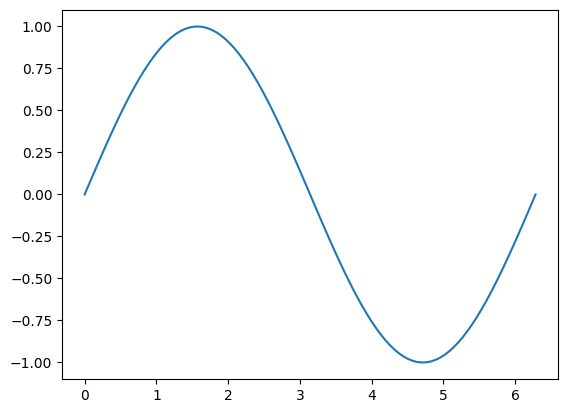

In [ ]:
xs = np.linspace(0, 2 * np.pi, 100)
plt.plot(xs, np.sin(xs))
plt.show()

**Вправа 16.** На одному графіку познач дві групи точок різними кольорами і додай легенду.

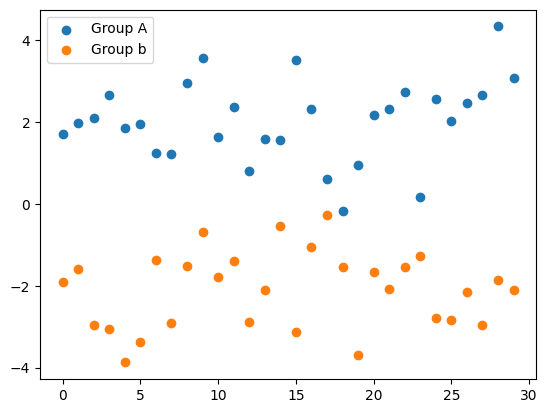

In [ ]:
group_a = np.random.randn(30) + 2
group_b = np.random.randn(30) - 2

plt.scatter(range(len(group_a)), group_a, color='C0', label='Group A')
plt.scatter(range(len(group_b)), group_b, color='C1', label='Group b')

plt.legend()
plt.show()

---
## Завдання 1. Лінійна регресія

Тренуємо базовий пайплайн на простій лінійній регресії з одним параметром.

$$y = w \cdot x + b + \varepsilon, \quad \varepsilon \sim \mathcal{N}(0, 1)$$

In [ ]:
TASK1_TRUE_W = 2.0
TASK1_TRUE_B = 1.0
TASK1_N = 300

x1 = torch.empty(TASK1_N, 1).uniform_(-5, 5)
noise = 1.0 * torch.randn(TASK1_N, 1)
y1 = TASK1_TRUE_W * x1 + TASK1_TRUE_B + noise

**Вправа 17.** Перш ніж будувати модель — подивись на самі дані.

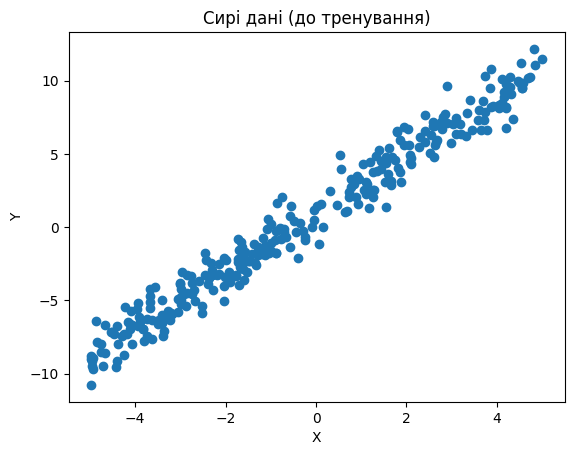

In [ ]:
plt.scatter(x1, y1)
plt.xlabel("X")
plt.ylabel("Y")
plt.title("Сирі дані (до тренування)")

plt.show()

**Вправа 18.** Розбий дані на train/val/test (70/15/15). Перемішай дані перед зрізом, інакше спліт вийде не випадковим.

In [ ]:
idxs = torch.randperm(TASK1_N)

x1_shuffled = x1[idxs]
y1_shuffled = y1[idxs]

train_size = int(0.7 * TASK1_N)
val_size = int(0.15 * TASK1_N)

x_train1 = x1_shuffled[:train_size]
y_train1 = y1_shuffled[:train_size]

x_val1 = x1_shuffled[train_size:train_size + val_size]
y_val1 = y1_shuffled[train_size:train_size + val_size]

x_test1 = x1_shuffled[train_size + val_size:]
y_test1 = y1_shuffled[train_size + val_size:]


print(f"train/val/test: {len(x_train1)}/{len(x_val1)}/{len(x_test1)}")


train/val/test: 210/45/45


**Вправа 19.** Нижче — готовий цикл навчання, кожен крок підписаний окремо. Просто запусти обидві комірки й подивись, як модель наближається до `true` за 100 епох (знімки кожні 30 епох).

In [ ]:
task1_model = torch.nn.Linear(in_features=1, out_features=1)
optimizer = torch.optim.SGD(task1_model.parameters(), lr=0.05)
loss_fn = torch.nn.MSELoss()

x_line = torch.linspace(-5, 5, 100).unsqueeze(1)  # сітка для візуалізації лінії
snapshots = []  # (epoch, w, b, y_line_pred) кожні 30 епох

for epoch in range(100):
    # обнулити градієнти з попереднього кроку
    optimizer.zero_grad()
    # forward -- прогноз моделі на поточних w, b
    y_pred = task1_model(x_train1)
    # loss -- наскільки прогноз відрізняється від y_train1
    loss = loss_fn(y_pred, y_train1)
    # backward -- градієнти loss за w і b
    loss.backward()
    # крок оптимізатора -- оновити w і b
    optimizer.step()

    if epoch % 30 == 0 or epoch == 99:
        with torch.no_grad():
            y_line_pred = task1_model(x_line)
        snapshots.append((epoch, task1_model.weight.item(), task1_model.bias.item(), y_line_pred))
        print(f"epoch {epoch:4d}  loss={loss.item():.6f}  "
              f"w={task1_model.weight.item():.4f} (true {TASK1_TRUE_W})  "
              f"b={task1_model.bias.item():.4f} (true {TASK1_TRUE_B})")


epoch    0  loss=10.796704  w=1.7971 (true 2.0)  b=-0.2009 (true 1.0)
epoch   30  loss=1.030498  w=1.9806 (true 2.0)  b=1.0221 (true 1.0)
epoch   60  loss=1.026565  w=1.9829 (true 2.0)  b=1.0764 (true 1.0)
epoch   90  loss=1.026557  w=1.9830 (true 2.0)  b=1.0788 (true 1.0)
epoch   99  loss=1.026557  w=1.9830 (true 2.0)  b=1.0789 (true 1.0)


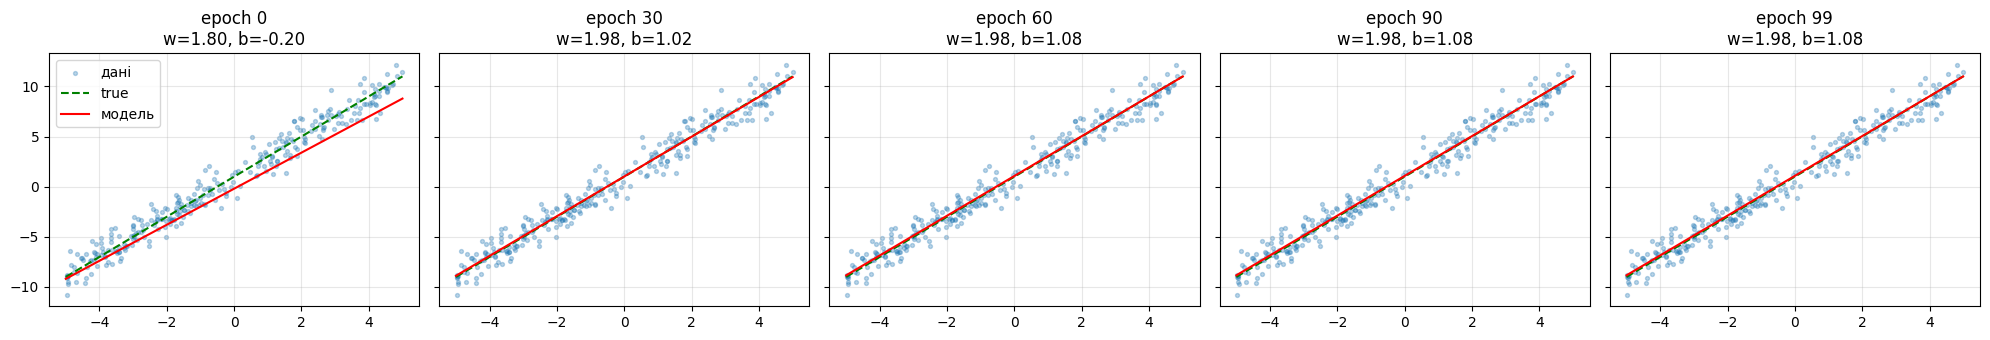

In [ ]:
with torch.no_grad():
    y_line_true = TASK1_TRUE_W * x_line + TASK1_TRUE_B

fig, axes = plt.subplots(1, len(snapshots), figsize=(4 * len(snapshots), 3.5), sharey=True)
for ax, (epoch, w, b, y_line_pred) in zip(axes, snapshots):
    ax.scatter(x1.numpy(), y1.numpy(), s=8, alpha=0.3, label="дані")
    ax.plot(x_line.numpy(), y_line_true.numpy(), "g--", label="true")
    ax.plot(x_line.numpy(), y_line_pred.numpy(), "r-", label="модель")
    ax.set_title(f"epoch {epoch}\nw={w:.2f}, b={b:.2f}")
    ax.grid(alpha=0.3)
axes[0].legend()
plt.tight_layout()
plt.show()


**Вправа 20.** Придумай власний напів-реальний сценарій лінійної залежності
(наприклад: кількість з'їдених пачок чіпсів на тиждень → індекс маси тіла;
години сну → продуктивність; щось своє). У markdown-комірці перед кодом
опиши сценарій: яку залежність ти
закладаєш ($w$, $b$) і чому саме такі значення видались тобі правдоподібними.
Згенеруй дані з шумом, збережи їх у CSV файл (за зразком відповідної частини лекції)
і натренуй лінійну регресію за тим самим патерном — спліт, цикл навчання, перевірка на test.
Організуй код тренування у логічні перевикористовувані функції.

В якості сценарія візьмемо залежність кількості ігр в рулетку і кількості грошей на рахунку (при ставці в 100 у. о.). Математичне очікування однієї гри -2.7 у.о., тому коефіцієнт $w$ буде рівним -2.7. Нехай середній стартовий капітал гравця буде 1000 у. о. з стандартним відхиленням 20, тоді коефіцієнт $b$ = 1000, $σ$ = 20

### Генеруємо синтетичні дані з шумом і зберігаємо у CSV


In [55]:
ROULETTE_TRUE_W = -2.7
ROULETTE_TRUE_B = 1000.0
ROULETTE_N = 500
ROULETTE_NOISE_STD = 20.0

played_games = np.random.uniform(0, 60, size=ROULETTE_N)
noise = np.random.normal(0, ROULETTE_NOISE_STD, size=ROULETTE_N)
money = ROULETTE_TRUE_W * played_games + ROULETTE_TRUE_B + noise

roulette_df = pd.DataFrame({
    'played_games': played_games,
    'money': money
})

csv_path = os.path.join(ARTIFACT_DIR, "dataset.csv")
roulette_df.to_csv(csv_path, index=False)
print("Дані збережено у:", csv_path)

Дані збережено у: /content/drive/MyDrive/ai_systems/lab1/dataset.csv


### Завантажуємо CSV як pandas-таблицю

In [56]:
loaded_df = pd.read_csv(csv_path)
print("Розмір таблиці:", loaded_df.shape)
loaded_df.head()

Розмір таблиці: (500, 2)


,played_games,money
0,0.073910,1018.505206
1,35.899636,893.195571
2,36.438387,877.727560
3,14.852397,970.155399
4,33.504760,881.778226


### Дивимось на дані на графіку

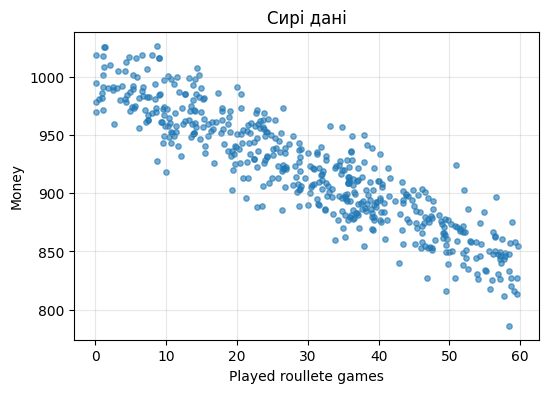

In [57]:
plt.figure(figsize=(6, 4))
plt.scatter(loaded_df["played_games"], loaded_df["money"], s=15, alpha=0.6)
plt.xlabel("Played roullete games")
plt.ylabel("Money")
plt.title("Сирі дані")
plt.grid(alpha=0.3)
plt.show()

### Тренуємо лінійну регресію

In [58]:
# Завантаження та нормалізація
x_raw = torch.tensor(loaded_df["played_games"].values, dtype=torch.float32).unsqueeze(1)
y = torch.tensor(loaded_df["money"].values, dtype=torch.float32).unsqueeze(1)

x_mean, x_std = x_raw.mean(), x_raw.std()
x = (x_raw - x_mean) / x_std

In [59]:
# Розбиваємо на train/val/test(70/15/15)
perm = torch.randperm(ROULETTE_N)
n_train = int(0.7 * ROULETTE_N)
n_val = int(0.15 * ROULETTE_N)

train_idx = perm[:n_train]
val_idx = perm[n_train:n_train + n_val]
test_idx = perm[n_train + n_val:]

x_train, y_train = x[train_idx], y[train_idx]
x_val, y_val = x[val_idx], y[val_idx]
x_test, y_test = x[test_idx], y[test_idx]

print(f"train/val/test: {len(x_train)}/{len(x_val)}/{len(x_test)}")

train/val/test: 350/75/75


In [66]:
# Тренування моделі
def get_eff_params(
    model: torch.nn.Module,
    x_mean: torch.Tensor,
    x_std: torch.Tensor
):
  w_norm = model.weight.item()
  b_norm = model.bias.item()
  mean_val = x_mean.item()
  std_val = x_std.item()

  w_eff = w_norm / std_val
  b_eff = b_norm - w_norm * mean_val / std_val

  return w_eff, b_eff

def train_step(
    model: torch.nn.Module,
    optimizer: torch.optim.Optimizer,
    loss_fn: torch.nn.Module,
    x_train: torch.Tensor,
    y_train: torch.Tensor
) -> float:
  optimizer.zero_grad()
  y_pred = model(x_train)
  loss = loss_fn(y_pred, y_train)

  loss.backward()
  optimizer.step()

  return loss.item()

def make_snapshot(
    epoch: int,
    model: torch.nn.Module,
    x_line: torch.Tensor,
    x_mean: torch.Tensor,
    x_std: torch.Tensor,
    loss_val: float,
    true_w: float,
    true_b: float
) -> tuple:
  with torch.no_grad():
    y_line_pred = model(x_line)
  w_eff, b_eff = get_eff_params(model, x_mean, x_std)

  print(f"epoch {epoch:4d}  loss={loss_val:.4f}  "
        f"w={w_eff:.4f} (true {true_w})  "
        f"b={b_eff:.4f} (true {true_b})")

  return (epoch, w_eff, b_eff, y_line_pred)

def train_model(
    model: torch.nn.Module,
    x_line_raw: torch.Tensor,
    x_train: torch.Tensor,
    y_train: torch.Tensor,
    x_mean: torch.Tensor,
    x_std: torch.Tensor,
    true_w: float,
    true_b: float,
    epochs: int = 100,
    lr: float = 0.05,
    snapshot_interval: int = 30
):
  optimizer = torch.optim.SGD(model.parameters(), lr=0.05)
  loss_fn = torch.nn.MSELoss()

  x_line = (x_line_raw - x_mean) / x_std
  snapshots = []

  for epoch in range(epochs):
      loss_val = train_step(model, optimizer, loss_fn, x_train, y_train)

      if epoch % snapshot_interval == 0 or epoch == epochs - 1:
          snapshot = make_snapshot(epoch, model, x_line, x_mean, x_std, loss_val, true_w, true_b)
          snapshots.append(snapshot)

  return snapshots

roulette_model = torch.nn.Linear(in_features=1, out_features=1)
x_line_raw = torch.linspace(0, 60, 100).unsqueeze(1)

snapshots = train_model(roulette_model, x_line_raw, x_train, y_train, x_mean, x_std, ROULETTE_TRUE_W, ROULETTE_TRUE_B)

epoch    0  loss=852172.8750  w=-0.3475 (true -2.7)  b=101.6009 (true 1000.0)
epoch   30  loss=1942.0491  w=-2.8707 (true -2.7)  b=970.1683 (true 1000.0)
epoch   60  loss=425.6417  w=-2.8385 (true -2.7)  b=1002.8061 (true 1000.0)
epoch   90  loss=422.8891  w=-2.8315 (true -2.7)  b=1004.0246 (true 1000.0)
epoch   99  loss=422.8848  w=-2.8311 (true -2.7)  b=1004.0540 (true 1000.0)


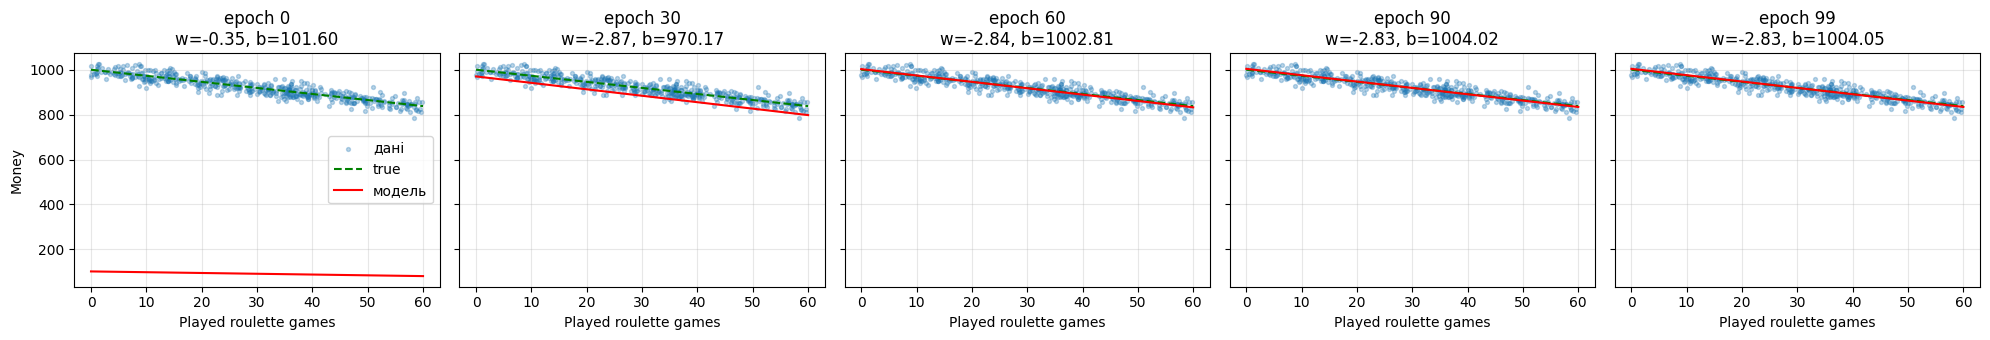

In [67]:
# Візуалізація
with torch.no_grad():
    y_line_true = ROULETTE_TRUE_W * x_line_raw + ROULETTE_TRUE_B

fig, axes = plt.subplots(1, len(snapshots), figsize=(4 * len(snapshots), 3.5), sharey=True)
for ax, (epoch, w_eff, b_eff, y_line_pred) in zip(axes, snapshots):
    ax.scatter(x_raw.numpy(), y.numpy(), s=8, alpha=0.3, label="дані")
    ax.plot(x_line_raw.numpy(), y_line_true.numpy(), "g--", label="true")
    ax.plot(x_line_raw.numpy(), y_line_pred.numpy(), "r-", label="модель")
    ax.set_title(f"epoch {epoch}\nw={w_eff:.2f}, b={b_eff:.2f}")
    ax.set_xlabel("Played roulette games")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Money")
axes[0].legend()
plt.tight_layout()
plt.show()

**Вправа 21.** Збережи натреновану модель на своєму гугл диску у файлі з назвою `model.pt`.
Збережений файл потрібно буде також здати разом з лабою.

In [68]:
model_path = os.path.join(ARTIFACT_DIR, "model.pt")

torch.save({
    "state_dict": roulette_model.state_dict(),
    "x_mean": x_mean.item(),
    "x_std": x_std.item(),
}, model_path)
print("Модель збережено у:", model_path)

Модель збережено у: /content/drive/MyDrive/ai_systems/lab1/model.pt


**Вправа 22.** Встанови [Gradio](https://gradio.app/)
```
!pip install -q gradio
import gradio as gr
```
Завантаж свою модель, збережену в попередній вправі і створи інтерактивну аппку.

In [69]:
!pip install -q gradio
import gradio as gr

In [70]:
checkpoint = torch.load(model_path, weights_only=False)

loaded_model = torch.nn.Linear(in_features=1, out_features=1)
loaded_model.load_state_dict(checkpoint["state_dict"])
loaded_model.eval()

loaded_x_mean = checkpoint["x_mean"]
loaded_x_std = checkpoint["x_std"]


def predict_money(played_games: float) -> float:
    x_input = torch.tensor([[played_games]], dtype=torch.float32)
    x_input_norm = (x_input - loaded_x_mean) / loaded_x_std
    with torch.no_grad():
        money_pred = loaded_model(x_input_norm)
    return round(money_pred.item(), 1)


demo = gr.Interface(
    fn=predict_money,
    inputs=gr.Slider(0, 100, value=10, step=1, label="Played roulette games"),
    outputs=gr.Number(label="Прогнозований залишок грошей"),
    title="Roulette -> Money",
    description="Лінійна регресія, натренована вище. Пересунь повзунок і подивись прогноз.",
)
demo.launch()


It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://5b2ad64344d7ee6b0c.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


---
### Як здавати лабу
У [форму](https://forms.gle/5qxRYshxKknBXDCz8) здати посилання на **публічний** репозиторій, який містить:
1. **Цей ноутбук з усіма виконаними вправами**. Ноутбук має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
2. **Додаткові скріншоти** по ходу виконання лаби (якими Ви доводите, що справді виконували цбю лабу).
3. Створений по ходу виконання лаби **csv файл** з даними і **pt файл** з моделлю.
4. Структура файлів на репозиторії, **точно дотримуйтесь, інакше не зарахується лаба**:
```
    /lab1/linear_models_lab.ipynb
    /lab1/screenshots/*
    /lab1/dataset.csv
    /lab1/model.pt
```